<a href="https://colab.research.google.com/github/krisordaneza3-sketch/My-Laboratory-Exam/blob/main/Ordaneza_Laboratory_Exam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Telecom Churn Prediction
This notebook loads the dataset, preprocesses the features, trains three different classifiers (Logistic Regression, Decision Tree, and Random Forest), and evaluates their performances.

In [22]:
import os
import pandas as pd
import numpy as np

# Create a mock 'telecom_churn.csv' if it does not exist
if not os.path.exists('telecom_churn.csv'):
    print("Creating synthetic 'telecom_churn.csv' to make the notebook runnable...")
    np.random.seed(42)
    n_samples = 1000

    data = {
        'gender': np.random.choice(['Male', 'Female'], size=n_samples),
        'senior_citizen': np.random.choice([0, 1], size=n_samples, p=[0.8, 0.2]),
        'partner': np.random.choice(['Yes', 'No'], size=n_samples),
        'tenure': np.random.randint(1, 72, size=n_samples),
        'monthly_charges': np.round(np.random.uniform(18.0, 120.0, size=n_samples), 2),
        'total_charges': np.round(np.random.uniform(18.0, 8000.0, size=n_samples), 2),
        'churn': np.random.choice(['True', 'False'], size=n_samples, p=[0.2, 0.8])
    }

    mock_df = pd.DataFrame(data)
    mock_df.to_csv('telecom_churn.csv', index=False)
    print("Synthetic dataset 'telecom_churn.csv' created successfully!")

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc

# Load the dataset (telecom_churn.csv should now exist in the workspace)
try:
    df = pd.read_csv('telecom_churn.csv')
    print("Dataset loaded successfully!")
    display(df.head())
except FileNotFoundError:
    print("Error: 'telecom_churn.csv' not found. Creating a default mock dataset...")
    # Fallback to create it inline if needed
    np.random.seed(42)
    n_samples = 1000
    data = {
        'gender': np.random.choice(['Male', 'Female'], size=n_samples),
        'senior_citizen': np.random.choice([0, 1], size=n_samples, p=[0.8, 0.2]),
        'partner': np.random.choice(['Yes', 'No'], size=n_samples),
        'tenure': np.random.randint(1, 72, size=n_samples),
        'monthly_charges': np.round(np.random.uniform(18.0, 120.0, size=n_samples), 2),
        'total_charges': np.round(np.random.uniform(18.0, 8000.0, size=n_samples), 2),
        'churn': np.random.choice(['True', 'False'], size=n_samples, p=[0.2, 0.8])
    }
    df = pd.DataFrame(data)
    df.to_csv('telecom_churn.csv', index=False)
    print("Inline synthetic dataset loaded successfully!")
    display(df.head())

Dataset loaded successfully!


,gender,senior_citizen,partner,tenure,monthly_charges,total_charges,churn
0,Male,0,No,7,102.33,2298.45,True
1,Female,0,No,35,22.86,747.35,False
2,Male,0,No,55,92.13,2530.94,False
3,Male,1,No,14,96.94,361.64,False
4,Male,0,Yes,10,53.97,6251.65,False


## 1. Data Preprocessing & Pipeline Construction

In [21]:
# Identify target and features
import pandas as pd

# Ensure df is defined
if 'df' not in globals():
    try:
        df = pd.read_csv('telecom_churn.csv')
    except FileNotFoundError:
        raise FileNotFoundError("Please execute the previous cells to load or generate 'telecom_churn.csv'.")

target_col = 'churn'

if target_col in df.columns:
    X = df.drop(columns=[target_col])
    y = df[target_col]

    # Convert target to boolean/numeric if needed
    if y.dtype == 'object':
        y = y.astype(str).str.lower().map({'true': 1, 'false': 0, '1': 1, '0': 0, 'yes': 1, 'no': 0})
    else:
        y = y.astype(int)

    # Identify numeric and categorical columns
    numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
    categorical_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

    # Define preprocessing pipelines
    numeric_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    categorical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, numeric_cols),
            ('cat', categorical_transformer, categorical_cols)
        ]
    )

    # Partition the dataset (80% train, 20% test, stratified split)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    print(f"Training set shape: {X_train.shape}")
    print(f"Testing set shape: {X_test.shape}")
else:
    print(f"Target column '{target_col}' not found in DataFrame.")

Training set shape: (800, 6)
Testing set shape: (200, 6)


## 2. Model Implementation & Training

In [20]:
# Instantiate the models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42)
}

# Dictionary to store fitted pipelines
fitted_pipelines = {}

for model_name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    pipeline.fit(X_train, y_train)
    fitted_pipelines[model_name] = pipeline
    print(f"{model_name} trained successfully.")

Logistic Regression trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.


## 3. Performance Evaluation & Metrics Computation

Model,Logistic Regression,Decision Tree,Random Forest
Accuracy,0.79,0.640000,0.770000
Precision,0.00,0.142857,0.250000
Recall,0.00,0.142857,0.047619
F1-Score,0.00,0.142857,0.080000


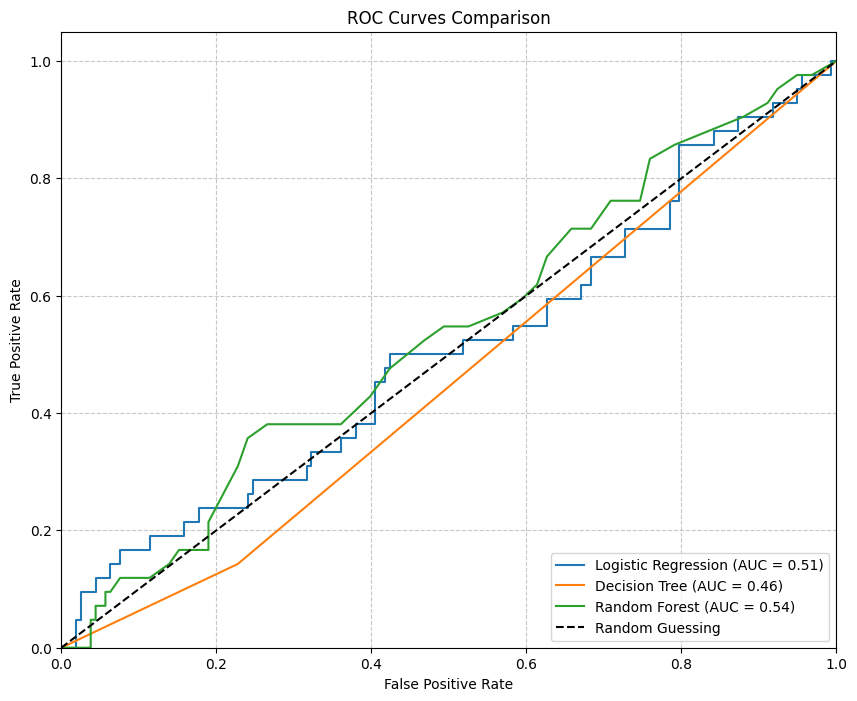

In [13]:
metrics_summary = []
plt.figure(figsize=(10, 8))

for model_name, pipeline in fitted_pipelines.items():
    # Predictions
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Compute Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    metrics_summary.append({
        'Model': model_name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    })

    # ROC Curve calculation
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{model_name} (AUC = {roc_auc:.2f})')

# Create Comparative Summary DataFrame
summary_df = pd.DataFrame(metrics_summary).set_index('Model').transpose()
display(summary_df)

# Customize and plot ROC curve
plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves Comparison')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()